# TexTag: Single-Image Inference and Timing

How the web app will use the model: load it once, then predict one image at a time and report how long it took.
Code: `src/textag/infer.py`.

- `load_model(path)` loads `models/textag.pt` (on CPU, ready to predict) and the class names.
- `predict(model, classes, image)` returns the **top 3** `(label, probability)` pairs and the **time in seconds**.

**What is timed:** preprocessing (resize, crop, normalize) + the model + softmax, i.e. what a user waits for.
Model loading is not included (the app does it once at startup).
The timer is `time.perf_counter()`, Python's most precise clock for measuring durations.

All timings below are on **CPU** (2 cores), similar to a free Hugging Face Space.

Sections:
1. Load the model
2. Predict a few test images
3. Timing over 50 images
4. First call vs later calls
5. Findings

## 1. Load the model

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from textag.data import dataset
from textag.infer import load_model, predict

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]
torch.set_num_threads(2)   # match a free Hugging Face Space (2 vCPU)

start = time.perf_counter()
model, classes = load_model(ROOT / "models" / "textag.pt")
print(f"model loaded in {time.perf_counter() - start:.2f} s, {len(classes)} classes")

model loaded in 0.18 s, 47 classes


## 2. Predict a few test images

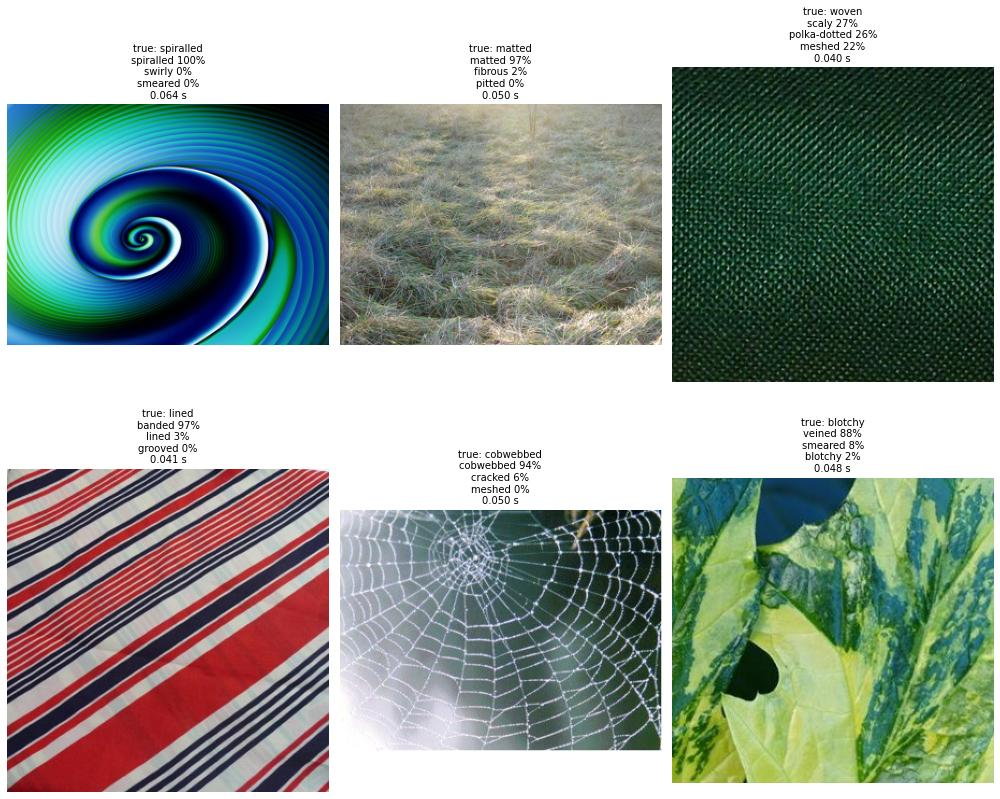

In [2]:
test_ds = dataset("test")
files = [Path(p) for p in test_ds._image_files]
true_labels = [classes[i] for i in test_ds._labels]

rng = np.random.default_rng(1)
pick = rng.choice(len(files), size=6, replace=False)

fig, axes = plt.subplots(2, 3, figsize=(14, 12))
for ax, i in zip(axes.flat, pick):
    preds, seconds = predict(model, classes, files[i])
    im = Image.open(files[i]).convert("RGB")
    im.thumbnail((300, 300))
    ax.imshow(im)
    ax.axis("off")
    lines = "\n".join(f"{label} {p:.0%}" for label, p in preds)
    ax.set_title(f"true: {true_labels[i]}\n{lines}\n{seconds:.3f} s", fontsize=10)
plt.tight_layout()
plt.show()

## 3. Timing over 50 images

In [3]:
times = []
for i in rng.choice(len(files), size=50, replace=False):
    _, seconds = predict(model, classes, files[i])
    times.append(seconds)
times = np.array(times)

pd.Series({
    "mean": times.mean(),
    "median": np.median(times),
    "fastest": times.min(),
    "slowest": times.max(),
}).map("{:.3f} s".format).to_frame("seconds per image")

,seconds per image
mean,0.043 s
median,0.042 s
fastest,0.036 s
slowest,0.059 s


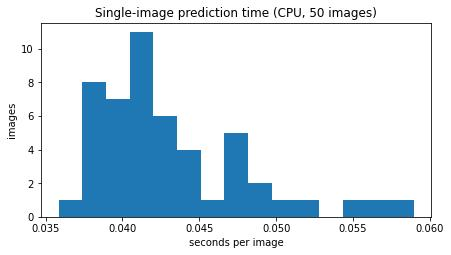

In [4]:
plt.figure(figsize=(7, 3.5))
plt.hist(times, bins=15)
plt.xlabel("seconds per image")
plt.ylabel("images")
plt.title("Single-image prediction time (CPU, 50 images)")
plt.show()

## 4. First call vs later calls

The very first prediction after loading is often slower (PyTorch does one-time setup).
Reload the model and time the first call against the next 10.

In [5]:
model, classes = load_model(ROOT / "models" / "textag.pt")
_, first = predict(model, classes, files[0])
later = [predict(model, classes, files[0])[1] for _ in range(10)]

pd.Series({"first call": first, "later calls (mean)": np.mean(later)}).map("{:.3f} s".format).to_frame("seconds")

,seconds
first call,0.041 s
later calls (mean),0.042 s


## 5. Findings

- **About 0.04–0.05 s per image** on 2 CPU cores (slowest ~0.06 s over 50 images), roughly 20–25 images per second. To a user, that feels instant. Exact numbers shift by a few milliseconds between runs; see the tables above.
- **Loading the model takes ~0.2 s** and happens once, when the app starts.
- **First call vs later calls:** no meaningful difference here (both ~0.04 s; within a few milliseconds of each other). The app still makes one cheap warm-up prediction at startup, just in case the first call is slower on the server.
- **Confidence tells you something:** correct predictions are usually confident (spiralled 100%, matted 97%, cobwebbed 94%). When the model is unsure, the probability is spread out (a woven image: scaly 27%, polka-dotted 26%, meshed 22%). It can still be confidently wrong on look-alike classes (lined → banded 97%), which is why the app shows the top 3, not just one label.